# 03 · First process discovery: comparing algorithms and abstraction levels

Group B · Process Mining Project WS26/27 · dataset **LaDe** (Cainiao last-mile, Jilin pickups)

Milestone M2 (`docs/milestones.md`): discover the pickup process from event log v1 (notebook 02) with more than one algorithm and more than one abstraction level, measure the quality of each model, and choose a candidate BPMN.

```
Event log v1 ──▶ 4 logs (2 case notions × 2 abstraction levels) ──▶ 3 algorithms ──▶ 12 models ──▶ quality ──▶ candidate BPMN
```

In [1]:
from pathlib import Path
import sys, warnings
import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from pm4py.util import constants

warnings.filterwarnings("ignore", message=".*PuLP.*")   # soundness check: scipy is enough for nets this small
warnings.filterwarnings("ignore", message=".*r4pm.*")
constants.SHOW_PROGRESS_BAR = False
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIG, TAB, MOD = (ROOT / p for p in ("data/processed", "outputs/figures", "outputs/tables", "outputs/models"))
for d in (FIG, TAB, MOD):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
from lade.discovery import ALGORITHMS, compare

XES = PROC / "lade_jl_pickup_parcel_v1.xes.gz"
assert XES.exists(), "run notebooks/02_event_log.ipynb first: it writes event log v1"
log = pm4py.read_xes(str(XES))
ACCEPT, PICKUP = "Accept order", "Pick up order"
print(f"{log['case:concept:name'].nunique():,} parcels, {len(log):,} events, {log['concept:name'].nunique()} activities")



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




261,801 parcels, 1,151,832 events, 6 activities


## 1. Four logs from event log v1

| Log | Case | Activities | Abstraction |
|---|---|---|---|
| **parcel, 6 activities** | parcel | accept, accept GPS fix, window opens, pick up, pickup GPS fix, window closes | event log v1 as it is |
| **parcel, 4 activities** | parcel | without the two GPS fixes | the remaining GPS fixes only mark a recording lag; leaving them out shows the plan-vs-reality core |
| **courier-day, single events** | courier and the date of the accept | accept, pick up | every event of the courier on that day (divergent, notebook 02 section 3) |
| **courier-day, batches** | courier-day | accept, pick up | consecutive equal activities merged into one batch event, as in notebook 01 |

In [2]:
no_gps = log[~log["concept:name"].str.endswith("GPS fix")]

# Courier-day: the parcel's accept date decides the day; accept before pick up when both share a minute
cd = log[log["concept:name"].isin([ACCEPT, PICKUP])].copy()
day = cd[cd["concept:name"] == ACCEPT].set_index("case:concept:name")["time:timestamp"].dt.strftime("%m%d")
cd["courier_day"] = cd["case:courier_id"].astype(str) + "_" + cd["case:concept:name"].map(day)
cd = cd.assign(rank=(cd["concept:name"] == PICKUP).astype(int)).sort_values(["time:timestamp", "rank"], kind="stable")
courier_day = pm4py.format_dataframe(cd.drop(columns=["case:concept:name", "@@index", "@@case_index", "rank"]),
                                     case_id="courier_day", activity_key="concept:name", timestamp_key="time:timestamp")
batches = courier_day[courier_day["concept:name"]
                      != courier_day.groupby("case:concept:name")["concept:name"].shift(fill_value="")]

logs = {"parcel, 6 activities": log, "parcel, 4 activities": no_gps,
        "courier-day, single events": courier_day, "courier-day, batches": batches}

def describe(l):
    counts = l.groupby("case:concept:name")["concept:name"].agg(tuple).value_counts()
    return {"cases": len(l["case:concept:name"].unique()), "activities": l["concept:name"].nunique(),
            "variants": len(counts), "top 3 variants, % of cases": round(100 * counts.head(3).sum() / counts.sum(), 1),
            "median events per case": int(l.groupby("case:concept:name").size().median())}

pd.DataFrame.from_dict({k: describe(l) for k, l in logs.items()}, orient="index")

,cases,activities,variants,"top 3 variants, % of cases",median events per case
"parcel, 6 activities",261801,6,27,77.9,4
"parcel, 4 activities",261801,4,6,99.8,4
"courier-day, single events",19004,2,9608,35.9,16
"courier-day, batches",19004,2,35,51.4,6


## 2. Algorithms and quality measures

**Algorithms** (as in the course discovery notebook):
- **Inductive Miner** (Leemans et al., 2013): always a sound, block-structured model; every trace fits.
- **Inductive Miner with a 20% noise filter** (IMf): leaves out infrequent behaviour, so the model gets more precise and loses some fitness.
- **Heuristics Miner** (Weijters et al., 2006): keeps only frequent, strong dependencies; the Petri net is not guaranteed to be sound.

**Measures**, all with token-based replay in PM4Py:
- **Fitness**: how much of the log the model can replay (100% = every event fits).
- **Precision**: how little behaviour the model allows that never occurs in the log (100% = nothing extra).
- **F1**: harmonic mean of fitness and precision, to rank models with one number.
- **Size**: transitions, places and arcs of the Petri net (smaller = simpler).
- **Sound**: the net can always finish properly (needed for a usable BPMN).

Replay on the courier-day logs is slow (a median of 16 events per case, long loops), so these two logs are measured on a fixed sample of courier-days. The models are still discovered from all courier-days.

In [3]:
# shortcut: courier-day quality on a 2,000-case sample (11%) (fixed seed); measure on all cases for the final BPMN (M4)
sample = pd.Series(courier_day["case:concept:name"].unique()).sample(2000, random_state=0)
eval_logs = {k: logs[k][logs[k]["case:concept:name"].isin(sample)] for k in ("courier-day, single events", "courier-day, batches")}

table, models = compare(logs, eval_logs)
table = table.round(1)
table.to_csv(TAB / "03_discovery_comparison.csv", index=False)
table

,log,algorithm,fitness %,fitting traces %,precision %,F1 %,transitions,places,arcs,sound
0,"parcel, 6 activities",Inductive Miner,100.0,100.0,56.5,72.2,11,13,30,True
1,"parcel, 6 activities","Inductive Miner, 20% noise filter",99.0,88.4,88.2,93.2,10,11,24,True
2,"parcel, 6 activities",Heuristics Miner,97.3,83.7,100.0,98.7,10,8,23,False
3,"parcel, 4 activities",Inductive Miner,100.0,100.0,100.0,100.0,6,8,14,True
4,"parcel, 4 activities","Inductive Miner, 20% noise filter",100.0,100.0,100.0,100.0,6,8,14,True
5,"parcel, 4 activities",Heuristics Miner,99.9,99.3,100.0,99.9,6,6,14,False
6,"courier-day, single events",Inductive Miner,100.0,100.0,69.3,81.9,10,8,20,True
7,"courier-day, single events","Inductive Miner, 20% noise filter",100.0,100.0,69.3,81.9,10,8,20,True
8,"courier-day, single events",Heuristics Miner,100.0,100.0,69.3,81.9,8,6,16,True
9,"courier-day, batches",Inductive Miner,100.0,100.0,100.0,100.0,5,5,10,True


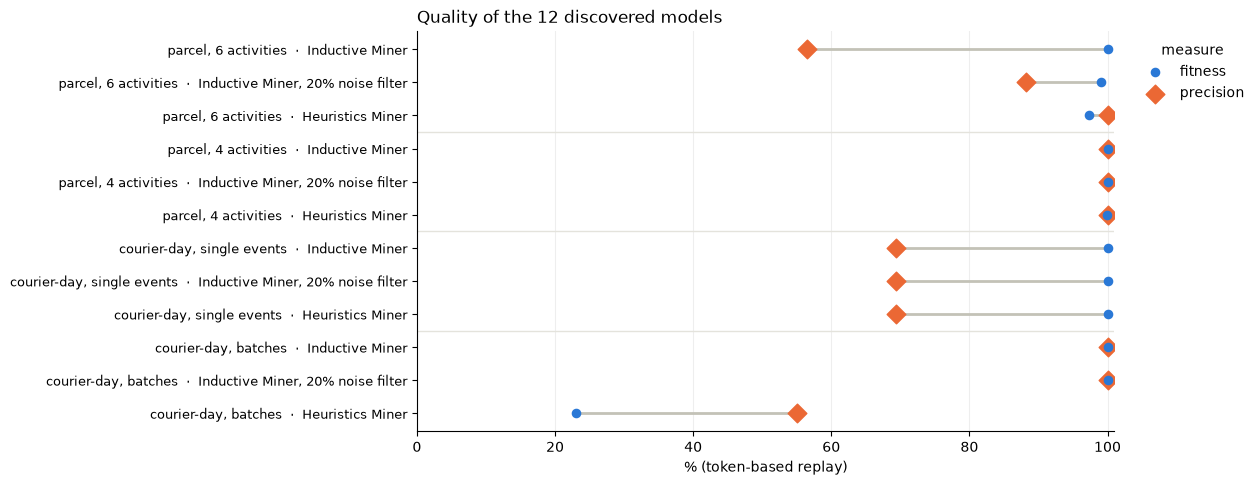

In [4]:
# Fitness and precision per model, in %; legend at the side
fig, ax = plt.subplots(figsize=(9, 5.2))
labels = (table["log"] + "  ·  " + table["algorithm"]).tolist()[::-1]
y = range(len(labels))
# precision drawn first and larger, so a fitness dot at the same value stays visible on top of it
for col, colour, marker, size in [("precision %", "#eb6834", "D", 90), ("fitness %", "#2a78d6", "o", 35)]:
    ax.scatter(table[col][::-1], y, s=size, color=colour, marker=marker, label=col.replace(" %", ""), zorder=3)
ax.hlines(y, table[["fitness %", "precision %"]].min(axis=1)[::-1], table[["fitness %", "precision %"]].max(axis=1)[::-1],
          color="#c3c2b7", lw=2, zorder=2)
for b in (2.5, 5.5, 8.5):
    ax.axhline(b, color="#e4e3dc", lw=1)
ax.set_yticks(list(y), labels, fontsize=9)
ax.set_xlabel("% (token-based replay)")
ax.set_xlim(0, 101)
ax.grid(axis="x", color="#eeeeee")
ax.spines[["top", "right"]].set_visible(False)
handles, names = ax.get_legend_handles_labels()
ax.legend(handles[::-1], names[::-1], title="measure", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax.set_title("Quality of the 12 discovered models", loc="left")
fig.savefig(FIG / "03_discovery_quality.png", dpi=150, bbox_inches="tight")

### Reading the comparison (`outputs/tables/03_discovery_comparison.csv`, `outputs/figures/03_discovery_quality.png`)

- **Parcel, 6 activities: the usual trade-off.** The Inductive Miner fits every parcel but has low precision (56.5%): to cover all 27 variants it puts the GPS fixes and the window into parallel blocks that allow many orders that never happen. The noise filter drops rare behaviour: 88.4% of the parcels fit exactly (log fitness 99.0%) and precision rises to 88.2%. The Heuristics Miner has the best F1 (98.7%), but its Petri net is **not sound**, so it cannot be used as a BPMN without manual repair.
- **Parcel, 4 activities: the core is fully structured.** Without the GPS fixes only 6 variants remain, and the Inductive Miner reaches 100% fitness and 100% precision. The imprecision of the 6-activity models therefore comes from the GPS fixes (the recording lag), not from the window and the pickup.
- **Courier-day, single events: only a loop fits.** All three algorithms find the same loop of accepts and pickups (fitness 100%, precision 69.3%). With two activities and a median of 16 events per courier-day, a loop is the only model that fits; it says little beyond "accepts and pickups repeat".
- **Courier-day, batches: the batching rhythm.** After merging consecutive equal activities (median 6 batches per courier-day), the Inductive Miner finds the exact pattern *(accept batch → pick-up batch)\** with 100% fitness and precision. The Heuristics Miner fails on this log (fitness 23.1%, not sound): accept → pick up and pick up → accept form a loop of length two, and the converted Petri net loses the link between the two activities.

## 3. Candidate BPMN

We take the model with the highest F1 among the **sound** models on the main log (parcel, 6 activities), convert it to BPMN and export it as a `.bpmn` file that opens in any BPMN editor (for example bpmn.io or Signavio).

In [5]:
main = table[(table["log"] == "parcel, 6 activities") & table["sound"]].sort_values("F1 %", ascending=False)
best = main.iloc[0]
net, im, fm = models["parcel, 6 activities", best["algorithm"]]
bpmn = pm4py.convert_to_bpmn(net, im, fm)
pm4py.write_bpmn(bpmn, str(MOD / "03_parcel_candidate.bpmn"))
pm4py.save_vis_bpmn(bpmn, str(FIG / "03_bpmn_parcel_candidate.png"))
assert len(pm4py.read_bpmn(str(MOD / "03_parcel_candidate.bpmn")).get_nodes()) == len(bpmn.get_nodes())
print(f"candidate: {best['algorithm']} · fitness {best['fitness %']}% · precision {best['precision %']}% · F1 {best['F1 %']}%")
if best["algorithm"].startswith("Inductive"):
    print(pm4py.discover_process_tree_inductive(log, noise_threshold=0.2 if "noise" in best["algorithm"] else 0.0))

candidate: Inductive Miner, 20% noise filter · fitness 99.0% · precision 88.2% · F1 93.2%


->( X( tau, 'Accept GPS fix' ), +( 'Accept order', X( tau, 'Pickup GPS fix' ) ), +( 'Pick up order', 'Window opens' ), 'Window closes' )


**Candidate (`outputs/models/03_parcel_candidate.bpmn`, `outputs/figures/03_bpmn_parcel_candidate.png`): Inductive Miner with a 20% noise filter**, the sound model with the highest F1 on the main log (the Heuristics Miner scores higher but is not sound).

How to read it:
1. An optional *Accept GPS fix* (a fix taken before the accept was recorded).
2. *Accept order*, in parallel with an optional *Pickup GPS fix*.
3. *Pick up order* and *Window opens* **in parallel**: the pickup can happen before the window opens (early, 29%) or inside it (on time, 70.8%).
4. *Window closes* always last.

What the noise filter leaves out, and what the model allows that never happens:
- **Late pickups (0.2%)** do not fit: the model forces *Window closes* to come after the pickup. Accepts after the window has opened (0.5%) do not fit either.
- The parallel block of step 2 allows a *Pickup GPS fix* before *Accept order*, which occurs in only 0.05% of the parcels. This is part of the missing precision and a candidate for a manual change to the BPMN in M4 (`docs/bpmn_manual_changes.md`).

## 4. How preprocessing and abstraction change the model

Three decisions from notebook 02 shape the discovered model:
- **Reordering equal timestamps** (Accept, Accept GPS fix, Window opens, Pick up, Pickup GPS fix, Window closes): without it, events that share a minute keep the column order of the raw file, which created 65 instead of 49 variants (notebook 02, section 6) and artificial orders in the model.
- **Merging GPS fixes in the same minute** (49 → 27 variants): the remaining fixes are still the main source of imprecision (56.5% vs 100% precision without them). Dropping them entirely gives a perfect model of the plan-vs-reality core, but hides the recording lag.
- **Case notion**: the parcel models show *when* a pickup happens relative to its window; the courier-day models only show the batching rhythm, and only after abstraction (batches) do they become precise. The courier-day view built here uses the date of the accept and has 19,004 courier-days (notebook 02 uses the dataset's `ds` column: 18,880).

## Open points for the next consultation
- Is token-based replay enough for the comparison, or should we use alignments for the candidate model (slower, more exact)?
- Is the Inductive Miner with a noise filter an acceptable candidate, given that it leaves out the rare late pickups?
- Should the courier-day view be measured on all courier-days or is a fixed sample acceptable for the comparison?